# Offline training: linear + quadratic + noise

Generate observations once, save them, and train PRISM from those files.
This uses the existing **SimplePolynomial** simulator from `minimal.ipynb`:
an optional linear term, an optional quadratic term, and Gaussian noise.

| File under `prism/train/` | Role in this notebook |
| --- | --- |
| `simulate.py` | `generate_datasets` calls the configured simulator and creates both data splits. |
| `offline_data.py` | `save_dataset` writes the files; `load_dataset` reads their arrays and metadata. |
| `dataset.py` | `FileDataset` exposes saved samples to the training data loader. |
| `train_script.py` | The existing trainer updates network weights, tracks EMA, and saves checkpoints. |
| `utils.py` | `load_checkpoint` rebuilds the network; `select_checkpoint_params` selects EMA weights. |

Run top to bottom with the repository's Python environment; see
[installation](../../docs/getting-started.md). This CPU example uses 128 training
samples, 32 validation samples, and 20 optimizer updates. It demonstrates file-based
training, not posterior accuracy. No data or checkpoints are downloaded.

In [1]:
import os
import tempfile
from pathlib import Path

# Set the device before importing JAX. Start with a fresh notebook kernel.
os.environ["JAX_PLATFORMS"] = "cpu"

%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

# Each run gets a new directory, so earlier datasets and checkpoints are preserved.
output_directory = Path(tempfile.mkdtemp(prefix="prism-offline-"))
data_directory = output_directory / "data"
run_directory = output_directory / "training"
print("Data and checkpoints:", output_directory)

Matplotlib is building the font cache; this may take a moment.


Data and checkpoints: /var/folders/m6/8wq1kfgs20d_7ckqj0l19m2r0000gn/T/prism-offline-asqbi219


## 1. Load the existing configuration

`cfg` is a configuration object. Hydra combines `conf/train.yaml` with
`conf/experiment/train/symbolic.yaml`, which selects the simulator and a small
compatible network. We only shorten the training run here.

The simulator implementation is in `prism/symbolic/simulators/__init__.py`:
`SimplePolynomial` combines the existing `Linear`, `Quadratic`, and `GaussianNoise`
classes. `conf/simulator/symbolic.yaml` selects that class, the prior, and the grid.

In [2]:
from hydra import compose, initialize_config_module
from omegaconf import OmegaConf

with initialize_config_module(version_base=None, config_module="conf"):
    cfg = compose(
        config_name="train",
        overrides=["+experiment/train=symbolic", "training.max_train_steps=20"],
    )

print(OmegaConf.to_yaml(cfg.simulator))
print("Seed:", cfg.run.seed)
print("Optimizer updates:", cfg.training.max_train_steps)

posterior_score: false
mask_prior:
  alpha: 1.0
  beta: 1.0
model_class: prism.symbolic.simulators.SimplePolynomial
num_points: 32
x_min: -1.0
x_max: 1.0

Seed: 0
Optimizer updates: 20


## 2. Simulate and save both datasets

`generate_datasets` in `prism/train/simulate.py` calls `build_simulator(cfg)` and
uses separate random keys for training and validation. It calls `save_dataset`
in `prism/train/offline_data.py` internally; we do not need a second saving step.

It also returns `training_config`: a copy of the configuration with its data loader
changed to **FileDataset**. That same configuration is saved as `training.yaml`.
The simulator and network settings are retained.

In [3]:
# Implementation: prism/train/simulate.py -> generate_datasets.
from prism.train.simulate import generate_datasets

training_config = generate_datasets(
    cfg,
    data_directory,
    train_size=128,
    validation_size=32,
    simulation_batch_size=32,
    device="cpu",
)

print("Training data loader:", training_config.training.dataloader.name)
print("Files:", sorted(path.name for path in data_directory.iterdir()))

Saved 128 samples to /private/var/folders/m6/8wq1kfgs20d_7ckqj0l19m2r0000gn/T/prism-offline-asqbi219/data/train.npz


Saved 32 samples to /private/var/folders/m6/8wq1kfgs20d_7ckqj0l19m2r0000gn/T/prism-offline-asqbi219/data/validation.npz


Training data loader: FileDataset
Files: ['simulation.yaml', 'train.npz', 'training.yaml', 'validation.npz']


The output contains four files:

```text
data/
├── train.npz        # 128 fixed training samples
├── validation.npz   # 32 independent validation samples
├── simulation.yaml  # Settings used to generate those samples
└── training.yaml    # Settings for training from the saved files
```

Generation refuses to overwrite an existing data directory. To train again on the
same samples, reuse these files and choose another training output directory.

## 3. Inspect the saved samples

`load_dataset` reads the arrays and generation metadata without calling the simulator.
For this preset, each sample contains:

| Field | Shape per sample | Meaning |
| --- | --- | --- |
| `mask_prior` | `(1,)` | The sampled prior value, lambda. |
| `model_mask` | `(3,)` | Active components: `[linear, quadratic, noise]`. |
| `theta` | `(3,)` | Unconstrained parameters for the two coefficients and noise scale. |
| `x` | `(32, 2)` | 32 observation points; columns are **coordinate** and **noisy signal**. |

Here `x` is the trainer's name for the full observation, not just its horizontal
coordinate. This preset supplies coordinate/signal pairs to the encoder; the
signal blocks used in `minimal.ipynb` are a different representation of the same
kind of data. The selected preset already matches the encoder to this input.

The simulator converts `theta` to coefficients and a positive noise scale. The
noise mask bit is always on in this example, but its scale is inferred.

In [4]:
# Implementation: prism/train/offline_data.py -> load_dataset.
from prism.train.offline_data import load_dataset

training_data, metadata = load_dataset(
    data_directory / "train.npz", simulator_config=cfg.simulator
)

for name, values in training_data.items():
    print(f"{name}: {values.shape}")
print("First mask [linear, quadratic, noise]:", training_data["model_mask"][0])
print("First lambda:", training_data["mask_prior"][0])
print("Generation record:", metadata["generation"])

mask_prior: (128, 1)
model_mask: (128, 3)
theta: (128, 3)
x: (128, 32, 2)
First mask [linear, quadratic, noise]: [ True  True  True]
First lambda: [0.84880435]
Generation record: {'dataset_key': [1797259609, 2579123966], 'seed': 0, 'simulation_batch_size': 32, 'split': 'train'}


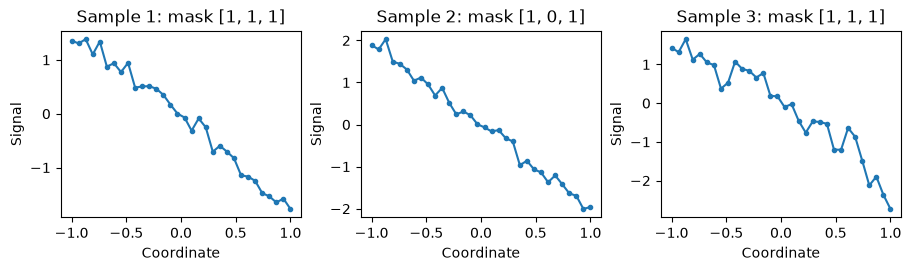

In [5]:
# Plot saved observations; this cell does not generate new samples.
fig, axes = plt.subplots(1, 3, figsize=(9, 2.6), layout="constrained")
for index, axis in enumerate(axes):
    observation = training_data["x"][index]
    mask = training_data["model_mask"][index].astype(int).tolist()
    axis.plot(observation[:, 0], observation[:, 1], ".-")
    axis.set(
        title=f"Sample {index + 1}: mask {mask}", xlabel="Coordinate", ylabel="Signal"
    )
plt.show()

## 4. Read samples through FileDataset

`FileDataset` in `prism/train/dataset.py` calls `load_dataset`, checks the requested
split and simulator configuration, and exposes indexed samples. It loads the data
into memory; it does not simulate observations.

Below we inspect one batch-sized slice. During training, `train_script.py` creates
this dataset automatically and uses its normal data loader to shuffle and batch it.

In [6]:
# Implementation: prism/train/dataset.py -> FileDataset.
from prism.train.dataset import FileDataset

training_dataset = FileDataset(
    data_directory / "train.npz",
    simulator_config=cfg.simulator,
    sha256=training_config.training.dataloader.train_dataset.sha256,
    split="train",
)
batch_size = training_config.training.dataloader.train_loader.batch_size
batch = training_dataset[:batch_size]

print("Saved training samples:", len(training_dataset))
print("Training batch size:", batch_size)
print("Batch shapes:", {name: values.shape for name, values in batch.items()})
np.testing.assert_array_equal(batch["theta"], training_data["theta"][:batch_size])

Saved training samples: 128
Training batch size: 8
Batch shapes: {'mask_prior': (8, 1), 'model_mask': (8, 3), 'theta': (8, 3), 'x': (8, 32, 2)}


## 5. Train using the saved configuration

This runs the existing `prism train` command, which dispatches to
`prism/train/train_script.py`. `sys.executable` uses the notebook kernel's Python
environment. The generated `training.yaml` selects the two NPZ files and records
their SHA-256 hashes, so training rejects a different dataset even on the first run.

Training reuses those observations for all 20 updates. It still imports the simulator
class to build the network, but does not call it to generate more observations.
Optimizer updates, validation, checkpointing, and EMA use the existing trainer.
Signal-block presets retain predictive RMSE by evaluating posterior parameter samples
on the configured grid. This coordinate-and-signal example does not enable that metric.
The trainer logs KSD as `nan` here because this optional metric is disabled.

In [7]:
import subprocess
import sys

command = [
    sys.executable,
    "-m",
    "prism",
    "train",
    "--config-path",
    str(data_directory),
    "--config-name",
    "training",
    f"hydra.run.dir={run_directory}",
]
result = subprocess.run(
    command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)
(output_directory / "training.log").write_text(result.stdout)
print(
    "\n".join(result.stdout.splitlines()[-10:])
    if result.returncode == 0
    else result.stdout
)
result.check_returncode()
print("Full log:", output_directory / "training.log")

[2026-09-17 11:40:51,739][prism.train.train_script][INFO] - Step 5, Loss mask: 1.410292625427246, Loss theta: 1.6169086694717407, sim. time: 0.0000s, read/wrt: 0.0000
[2026-09-17 11:40:51,747][prism.train.train_script][INFO] - Step 10, Loss mask: 1.3547440767288208, Loss theta: 1.313647985458374, sim. time: 0.0000s, read/wrt: 0.0000
[2026-09-17 11:40:51,753][prism.train.train_script][INFO] - Step 15, Loss mask: 1.2219570875167847, Loss theta: 1.2532016038894653, sim. time: 0.0000s, read/wrt: 0.0000
[2026-09-17 11:40:51,760][prism.train.train_script][INFO] - Step 20, Loss mask: 1.1712266206741333, Loss theta: 1.2857965230941772, sim. time: 0.0000s, read/wrt: 0.0000
[2026-09-17 11:40:51,760][prism.train.train_script][INFO] - Evaluating model at step 20
[2026-09-17 11:40:52,600][prism.train.train_script][INFO] - Mask NLL: 2.0793821811676025, Theta NLL: 3.401289701461792
[2026-09-17 11:40:52,600][prism.train.train_script][INFO] - KSD: nan, p-value: nan
[2026-09-17 11:40:52,686][prism.train

## 6. Restore the checkpoint and EMA weights

`load_checkpoint` in `prism/train/utils.py` rebuilds the network from its saved
configuration and reads the requested checkpoint. Select the EMA weights explicitly
and switch the restored model to evaluation mode. EMA is a moving average of the
network weights maintained during training.

In [8]:
# Implementations: prism/train/utils.py and prism/train/checkpointing.py.
from flax import nnx

from prism.train.utils import load_checkpoint, select_checkpoint_params

checkpoint, model, simulator_class = load_checkpoint(run_directory, which="latest")
nnx.update(model, select_checkpoint_params(checkpoint, "params_ema"))
model.eval()

assert int(checkpoint["step"]) == training_config.training.max_train_steps
print("Restored step:", int(checkpoint["step"]))
print("Simulator:", simulator_class.__name__)
print("Weights: params_ema")

Restored step: 20
Simulator: SimplePolynomial
Weights: params_ema


## 7. Use the restored model on a saved validation observation

Read one held-out observation, sample its component mask, then sample parameters
conditioned on that mask. The model's sampling methods are in
`prism/nn/model.py`, which is used by the polynomial preset
for symbolic data as well. `nnx.jit` compiles these calls; it does not train the model.

This final check demonstrates that the restored checkpoint can be used for inference.
Twenty updates are not enough to assess the quality of the inferred mask or parameters.

In [9]:
import jax

validation_data, _ = load_dataset(data_directory / "validation.npz")
observation = validation_data["x"][0]
prior_value = validation_data["mask_prior"][0]


@nnx.jit
def sample_posterior(model, observation, prior_value):
    mask_key, theta_key = jax.random.split(jax.random.key(1))
    mask = model.sample_mask(mask_key, x=observation, mask_prior=prior_value)
    theta = model.sample_theta(theta_key, x=observation, model_mask=mask, num_steps=8)
    return mask, theta


sampled_mask, sampled_theta = sample_posterior(model, observation, prior_value)
assert np.isfinite(sampled_theta).all()
print("Sampled mask [linear, quadratic, noise]:", np.asarray(sampled_mask))
print("Sampled theta shape:", sampled_theta.shape)

Sampled mask [linear, quadratic, noise]: [ True False  True]
Sampled theta shape: (3,)


## The same workflow from a terminal

The two commands below use the same simulator and training settings. Run them from
your installed repository environment with a new output directory.

```bash
prism simulate +experiment/train=symbolic training.max_train_steps=20 \
  --output results/polynomial_offline_data \
  --train-size 128 --validation-size 32 --simulation-batch-size 32

JAX_PLATFORMS=cpu prism train \
  --config-path "$PWD/results/polynomial_offline_data" --config-name training \
  hydra.run.dir="$PWD/results/polynomial_offline_training"
```

To train longer on the same files, change `training.max_train_steps` in the second
command. Changing the simulator or its prior requires generating a matching dataset.
For custom symbolic classes, see the [training guide](../../docs/guides/training.md#use-your-own-symbolic-model).